# 10 - Results and discussion

Addresses the last two points of the supervisor review:

> * Now I arrived at "Stage 4" - please indicate if things are outdated/wrong.
> * A proper discussion of the results is missing.

This notebook **needs no GPU**. It loads the CSV and JSON artifacts written by notebooks
06-09 and produces the figures and tables that span more than one experiment - the ones
that cannot be made inside any single upstream notebook:

* attack success as a function of the operating threshold (06 x 08)
* explanation faithfulness before and after the attack, against the random floor (07 x 09)
* transfer across explanation families (09)

## Which notebooks are current

| Notebook | Status | Superseded by |
|---|---|---|
| `01-data-and-model` | outdated - 900 pairs, threshold 0.30 | **`06`** |
| `02-xai` | outdated - qualitative only | **`07`** |
| `03-attacks` | **wrong** - gradient-ascent sign bug, `flip_rate = 0.00` everywhere | **`08`**, **`09`** |
| `04-explanation-attack-v2` | partly superseded - sign fixed, but 40 pairs, genuine only, one-sided constraint | **`09`** |
| `05-xssab-and-transfer` | partly superseded - 20 pairs, `grad x input` stand-in for xSSAB | **`09`** |
| `06-protocol-and-threshold` | **current** | |
| `07-xai-faithfulness` | **current** | |
| `08-decision-attacks` | **current** | |
| `09-explanation-attack` | **current** | |

## How to run this on Kaggle

This notebook consumes files written by notebooks 06-09. **Seven are required** (all
small - about 1.8 MB in total, dominated by `explanation_attack.csv`); the rest are loaded
only so you can explore them and may be absent.

**Option A - attach the notebook outputs.** In the editor sidebar choose
*Add Input -> Notebooks*, and add notebooks 06, 07, 08 and 09. They must have been saved
with *Save Version -> Save & Run All (Commit)*: the `/kaggle/working` of an interactive
session is not attachable. Files then appear under `/kaggle/input/<notebook-slug>/`.

**Option B - upload one dataset.** Download the outputs, put all of them in one folder,
then *Datasets -> New Dataset* and drag them in. In this notebook, *Add Input -> Datasets*
and select it. This works whether or not the notebooks were committed, and it is one
upload instead of four attachments.

The loader searches `/kaggle/working` and everything under `/kaggle/input` recursively, so
either layout works. Files renamed with a notebook-number prefix (`06_thresholds.json`,
`09_explanation_attack.csv`) are matched automatically, so you can keep them organised.

## CONFIG

In [5]:
import os

# Where to look for the artifacts written by notebooks 06-09.
SEARCH_DIRS = ["/kaggle/working", "/kaggle/input", "./", "../"]
OUTPUT_DIR = "/kaggle/working/"

## Imports

In [6]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Locate the artifacts

Nothing here recomputes anything, so a missing file is a hard stop for whichever section
needs it rather than a silent gap. The table below tells you exactly what was found.

In [7]:
# (filename, produced by, required)  -  only the "required" ones drive a figure
# or a table below; the rest are loaded so you can explore them, and their
# absence is harmless.
WANTED = [
    ("thresholds.json",                           "06", True),
    ("operating_points.csv",                      "06", True),
    ("xai_faithfulness_summary.csv",              "07", True),
    ("decision_attack_summary.csv",               "08", True),
    ("decision_attack_threshold_sensitivity.csv", "08", True),
    ("explanation_attack_summary.csv",            "09", True),
    ("explanation_attack.csv",                    "09", True),
    ("fold_accuracy.csv",                         "06", False),
    ("fold_separation.csv",                       "06", False),
    ("xai_faithfulness_pairs.csv",                "07", False),
    ("xai_curves_mean.npz",                       "07", False),
    ("decision_attacks.csv",                      "08", False),
    ("explanation_attack_curves.npz",             "09", False),
    ("explanation_attack_config.json",            "09", False),
]


def find_artifact(name):
    # Locate an artifact anywhere under SEARCH_DIRS.  Matches the exact
    # filename first, then any file ending in "_<name>" or "-<name>", so a
    # copy renamed to 09_explanation_attack.csv while being organised on
    # disk is still found.
    prefixed = []
    for root in SEARCH_DIRS:
        if not os.path.isdir(root):
            continue
        for dirpath, _, filenames in os.walk(root):
            if name in filenames:
                return os.path.join(dirpath, name)
            for fn in filenames:
                if fn.endswith("_" + name) or fn.endswith("-" + name):
                    prefixed.append(os.path.join(dirpath, fn))
    return prefixed[0] if prefixed else None


def short(path):
    if path is None:
        return "NOT FOUND"
    return path.replace("/kaggle/input/", "").replace("/kaggle/working/", "working/")


PATHS = {}
print(f"{'artifact':>46} {'from':>5} {'need':>6}  found at")
print("-" * 92)
for name, nb, required in WANTED:
    PATHS[name] = find_artifact(name)
    print(f"{name:>46} {nb:>5} {'yes' if required else 'no':>6}  {short(PATHS[name])}")

missing = [n for n, _, req in WANTED if req and PATHS[n] is None]
print()
if missing:
    print(f"{len(missing)} REQUIRED artifact(s) missing:")
    for m in missing:
        print(f"   {m}")
    print()
    print("Attach them with  Add Input -> Notebooks  (add notebooks 06-09; each must have")
    print("been saved with Save Version -> Save & Run All), or upload them as one Dataset")
    print("via  Add Input -> Datasets.  Copies renamed with a notebook-number prefix such")
    print("as 06_thresholds.json are matched automatically.")
else:
    print("All required artifacts found.")


def load_csv(name):
    return pd.read_csv(PATHS[name]) if PATHS[name] else None


def load_json(name):
    if not PATHS[name]:
        return None
    with open(PATHS[name]) as fh:
        return json.load(fh)


def load_npz(name):
    return np.load(PATHS[name]) if PATHS[name] else None


thresholds = load_json("thresholds.json")
op_df = load_csv("operating_points.csv")
fold_acc = load_csv("fold_accuracy.csv")
fold_sep = load_csv("fold_separation.csv")
xai_sum = load_csv("xai_faithfulness_summary.csv")
xai_pairs = load_csv("xai_faithfulness_pairs.csv")
xai_curves = load_npz("xai_curves_mean.npz")
dec_sum = load_csv("decision_attack_summary.csv")
dec_sens = load_csv("decision_attack_threshold_sensitivity.csv")
dec_pairs = load_csv("decision_attacks.csv")
exp_sum = load_csv("explanation_attack_summary.csv")
exp_pairs = load_csv("explanation_attack.csv")
exp_curves = load_npz("explanation_attack_curves.npz")
exp_cfg = load_json("explanation_attack_config.json")

                                      artifact  from   need  found at
--------------------------------------------------------------------------------------------
                               thresholds.json    06    yes  datasets/xitij27/kaggle-nb10-input/06_thresholds.json
                          operating_points.csv    06    yes  datasets/xitij27/kaggle-nb10-input/06_operating_points.csv
                  xai_faithfulness_summary.csv    07    yes  datasets/xitij27/kaggle-nb10-input/07_xai_faithfulness_summary.csv
                   decision_attack_summary.csv    08    yes  datasets/xitij27/kaggle-nb10-input/08_decision_attack_summary.csv
     decision_attack_threshold_sensitivity.csv    08    yes  datasets/xitij27/kaggle-nb10-input/08_decision_attack_threshold_sensitivity.csv
                explanation_attack_summary.csv    09    yes  datasets/xitij27/kaggle-nb10-input/09_explanation_attack_summary.csv
                        explanation_attack.csv    09    yes  datasets/xitij2

## 1. The protocol

The foundation everything else is measured against: how many pairs, how well the model
separates them, and where the decision threshold sits.

In [8]:
if thresholds:
    print("Dataset")
    print(f"  pairs            : {thresholds['n_pairs']:,} "
          f"({thresholds['n_genuine']:,} genuine / {thresholds['n_imposter']:,} imposter)")
    print(f"  probe selection  : PROBE_SIDE={thresholds['probe_side']!r} "
          f"seed={thresholds['probe_seed']}")
    print("\nRecognition performance")
    print(f"  EER              : {thresholds['eer']:.3%} at threshold "
          f"{thresholds['eer_threshold']:.4f}")
    print(f"  LFW 10-fold acc  : {thresholds['lfw_10fold_accuracy_mean']:.4%} "
          f"+/- {thresholds['lfw_10fold_accuracy_std']:.4%}")
    print("\nOperating points")
    if op_df is not None:
        print(op_df.to_string(index=False,
                              float_format=lambda v: f"{v:.5f}"))
else:
    print("thresholds.json not found - run notebook 06.")

Dataset
  pairs            : 6,000 (3,000 genuine / 3,000 imposter)
  probe selection  : PROBE_SIDE='random' seed=20260728

Recognition performance
  EER              : 0.300% at threshold 0.2136
  LFW 10-fold acc  : 99.8000% +/- 0.2460%

Operating points
operating_point  threshold     fmr    fnmr  accuracy
            EER    0.21356 0.00300 0.00300   0.99700
       FMR<=0.1    0.09426 0.10000 0.00167   0.94917
      FMR<=0.01    0.16826 0.01000 0.00267   0.99367
     FMR<=0.001    0.24829 0.00100 0.00300   0.99800
   legacy (0.3)    0.30000 0.00033 0.00333   0.99817


## 2. Decision attacks - the direction check

The plot the review asked for, in one place: genuine pairs must move **left** (similarity
down), imposter pairs **right** (similarity up). The bar chart makes the sign visible at
a glance; the table underneath gives the success rates at every operating point.

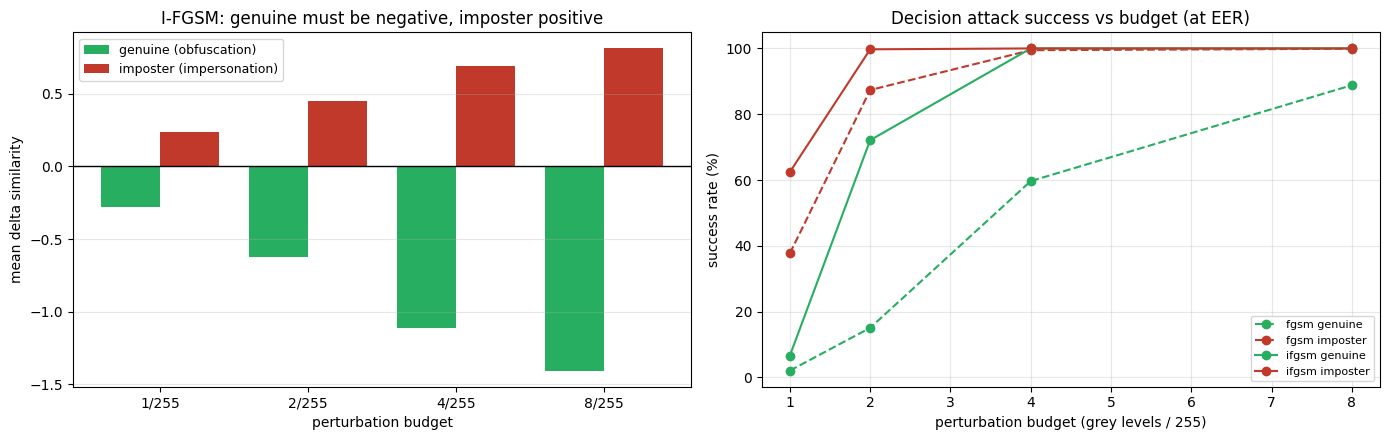

sign check: ALL CORRECT

Success rate vs operating threshold (I-FGSM)
operating_point  threshold  obfuscation  impersonation
            EER     0.2134       1.0000         1.0000
       FMR<=0.1     0.0942       0.9977         1.0000
      FMR<=0.01     0.1684       0.9997         1.0000
     FMR<=0.001     0.2484       1.0000         1.0000


In [9]:
if dec_sum is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    ax = axes[0]
    for direction, color in [("genuine", "#27ae60"), ("imposter", "#c0392b")]:
        sub = dec_sum[(dec_sum.attack == "ifgsm") & (dec_sum.direction == direction)]
        ax.bar(np.arange(len(sub)) + (0.2 if direction == "imposter" else -0.2),
               sub.mean_delta_sim, 0.4, color=color,
               label=f"{direction} ({'obfuscation' if direction == 'genuine' else 'impersonation'})")
        ax.set_xticks(np.arange(len(sub)))
        ax.set_xticklabels([f"{e:g}/255" for e in sub.eps_255])
    ax.axhline(0, color="k", lw=1)
    ax.set_ylabel("mean delta similarity")
    ax.set_xlabel("perturbation budget")
    ax.set_title("I-FGSM: genuine must be negative, imposter positive")
    ax.legend(fontsize=9); ax.grid(alpha=0.3, axis="y")

    ax = axes[1]
    for attack, ls in [("fgsm", "--"), ("ifgsm", "-")]:
        for direction, color in [("genuine", "#27ae60"), ("imposter", "#c0392b")]:
            sub = dec_sum[(dec_sum.attack == attack) & (dec_sum.direction == direction)]
            ax.plot(sub.eps_255, sub.success * 100, ls, marker="o", color=color,
                    label=f"{attack} {direction}")
    ax.set_xlabel("perturbation budget (grey levels / 255)")
    ax.set_ylabel("success rate (%)")
    ax.set_title("Decision attack success vs budget (at EER)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "10_decision_attacks.png"), dpi=140, bbox_inches="tight")
    plt.show()

    bad = dec_sum[~dec_sum.sign_ok]
    print("sign check:", "ALL CORRECT" if len(bad) == 0 else f"WRONG for\n{bad}")

if dec_sens is not None:
    print("\nSuccess rate vs operating threshold (I-FGSM)")
    print(dec_sens.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

## 3. Explanation faithfulness: before, after, and the floor

The central figure of the project. For each explanation method, three bars: the
unattacked map (notebook 07 / 09 "before"), the attacked map (notebook 09 "after"), and
the random-saliency control (notebook 07) that marks what "no explanation at all" scores.

The distance the attacked bar travels toward the random bar is how much of the
explanation's value was destroyed.

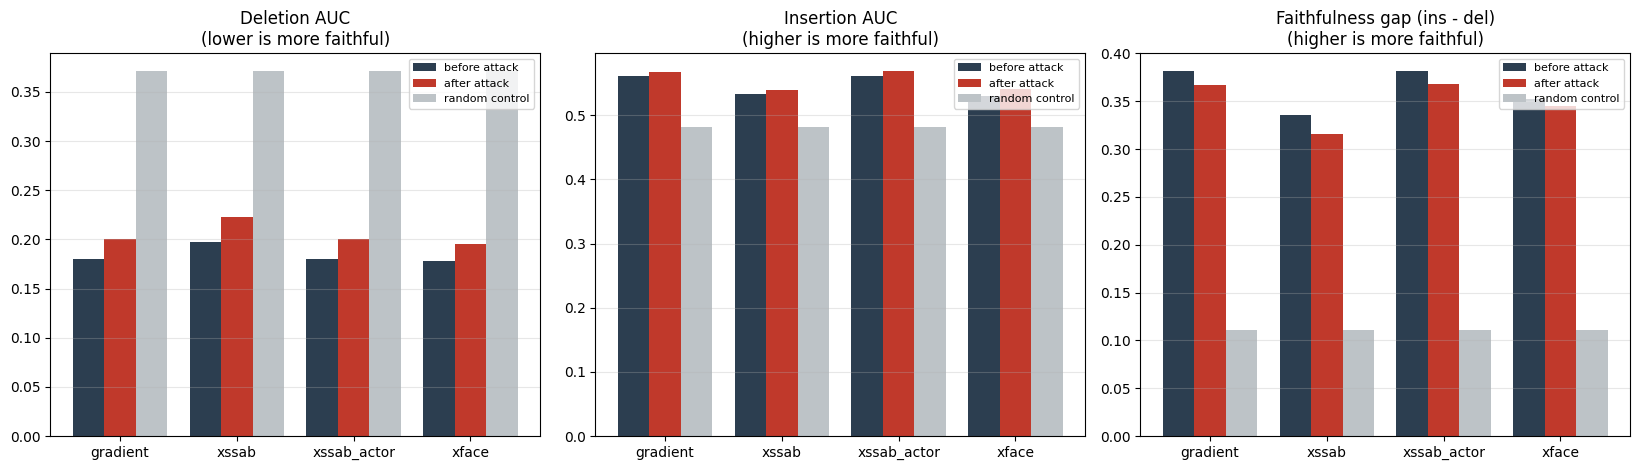

How far each explanation moved toward the 'no information' floor
    method  gap before  gap after   random  % of value lost
------------------------------------------------------------
  gradient      0.3813     0.3668   0.1111             5.4%
     xssab      0.3358     0.3159   0.1111             8.8%
xssab_actor      0.3812     0.3680   0.1111             4.9%
     xface      0.3524     0.3456   0.1111             2.8%


In [10]:
if exp_sum is not None and xai_sum is not None:
    rand_row = xai_sum[(xai_sum.subset == "genuine and accepted at EER")
                       & (xai_sum.method == "random")]
    if len(rand_row) == 0:
        rand_row = xai_sum[(xai_sum.subset == "genuine") & (xai_sum.method == "random")]
    rand_del = float(rand_row.del_auc.iloc[0])
    rand_ins = float(rand_row.ins_auc.iloc[0])
    rand_gap = rand_ins - rand_del

    methods = list(exp_sum.method)
    x = np.arange(len(methods))
    w = 0.27

    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

    for ax, col_b, col_a, floor, title, better in [
        (axes[0], "del_auc_before", "del_auc_after", rand_del,
         "Deletion AUC", "lower is more faithful"),
        (axes[1], "ins_auc_before", "ins_auc_after", rand_ins,
         "Insertion AUC", "higher is more faithful"),
        (axes[2], "gap_before", "gap_after", rand_gap,
         "Faithfulness gap (ins - del)", "higher is more faithful"),
    ]:
        ax.bar(x - w, exp_sum[col_b], w, label="before attack", color="#2c3e50")
        ax.bar(x, exp_sum[col_a], w, label="after attack", color="#c0392b")
        ax.bar(x + w, [floor] * len(methods), w, label="random control", color="#bdc3c7")
        ax.set_xticks(x); ax.set_xticklabels(methods)
        ax.set_title(f"{title}\n({better})")
        ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "10_faithfulness_before_after.png"),
                dpi=140, bbox_inches="tight")
    plt.show()

    print("How far each explanation moved toward the 'no information' floor")
    print(f"{'method':>10} {'gap before':>11} {'gap after':>10} {'random':>8} "
          f"{'% of value lost':>16}")
    print("-" * 60)
    for _, r in exp_sum.iterrows():
        span = r.gap_before - rand_gap
        lost = (r.gap_before - r.gap_after) / span * 100 if span else float("nan")
        print(f"{r.method:>10} {r.gap_before:>11.4f} {r.gap_after:>10.4f} "
              f"{rand_gap:>8.4f} {lost:>15.1f}%")
else:
    print("Need explanation_attack_summary.csv (09) and xai_faithfulness_summary.csv (07).")

## 4. Transfer across explanation families

The attack only ever saw the gradient map. This is where we find out whether it corrupted
the model's reasoning or just one way of drawing it.

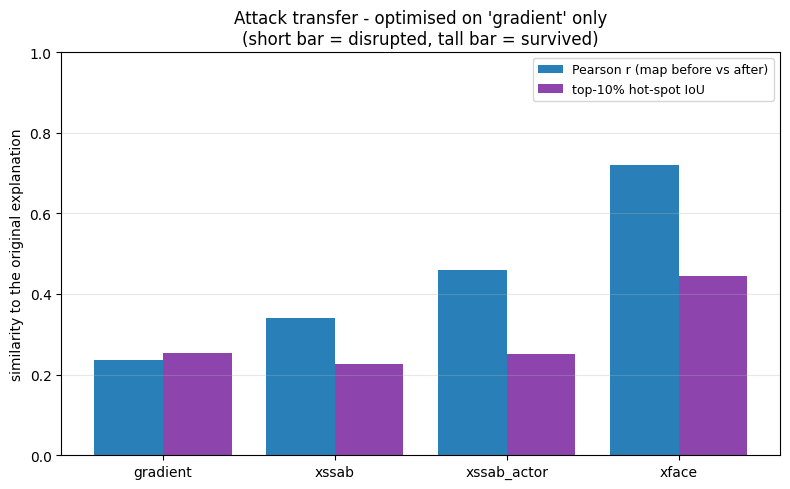

     method  pearson  topk_iou  del_auc_before  del_auc_after  ins_auc_before  ins_auc_after
   gradient   0.2359    0.2528          0.1799         0.2007          0.5612         0.5675
      xssab   0.3407    0.2252          0.1976         0.2232          0.5334         0.5392
xssab_actor   0.4584    0.2513          0.1801         0.2005          0.5613         0.5685
      xface   0.7198    0.4434          0.1777         0.1952          0.5301         0.5408


In [11]:
if exp_sum is not None:
    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(len(exp_sum))
    ax.bar(x - 0.2, exp_sum.pearson, 0.4, label="Pearson r (map before vs after)",
           color="#2980b9")
    ax.bar(x + 0.2, exp_sum.topk_iou, 0.4, label="top-10% hot-spot IoU", color="#8e44ad")
    ax.set_xticks(x); ax.set_xticklabels(exp_sum.method)
    ax.set_ylim(0, 1)
    ax.set_ylabel("similarity to the original explanation")
    ax.set_title("Attack transfer - optimised on 'gradient' only\n"
                 "(short bar = disrupted, tall bar = survived)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "10_transfer.png"), dpi=140, bbox_inches="tight")
    plt.show()

    print(exp_sum[["method", "pearson", "topk_iou", "del_auc_before", "del_auc_after",
                   "ins_auc_before", "ins_auc_after"]].to_string(
        index=False, float_format=lambda v: f"{v:.4f}"))

## 5. The decision really did survive

The counterpart to section 3: the explanation collapsed, but the thing the explanation
was supposed to justify did not move.

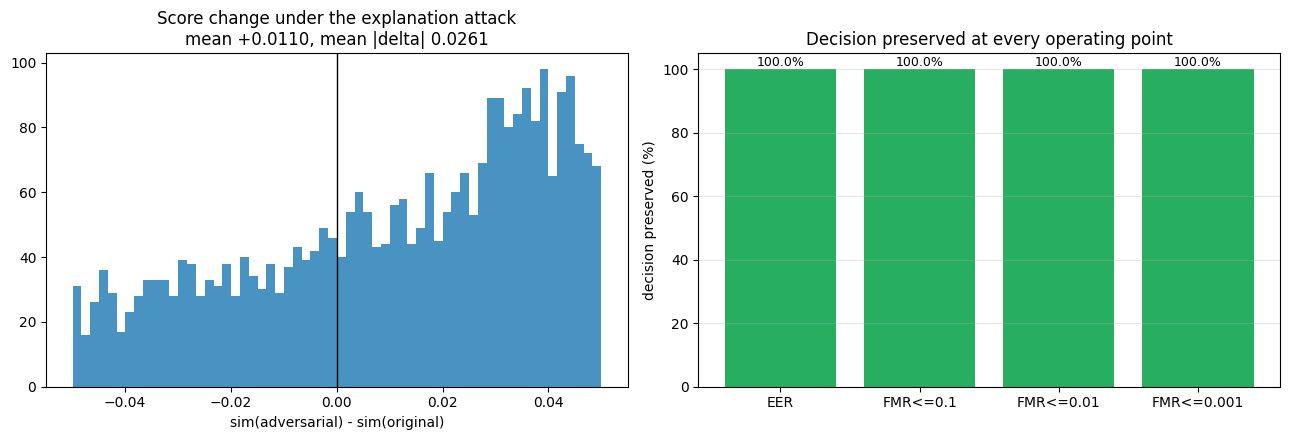

perturbation: mean Linf = 2.67/255, mean L2 = 2.551


In [12]:
if exp_pairs is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].hist(exp_pairs.delta_sim, bins=60, color="#2980b9", alpha=0.85)
    axes[0].axvline(0, color="k", lw=1)
    axes[0].set_xlabel("sim(adversarial) - sim(original)")
    axes[0].set_title(f"Score change under the explanation attack\n"
                      f"mean {exp_pairs.delta_sim.mean():+.4f}, "
                      f"mean |delta| {exp_pairs.delta_sim.abs().mean():.4f}")

    pres_cols = [c for c in exp_pairs.columns if c.startswith("preserved_")]
    names = [c.replace("preserved_", "") for c in pres_cols]
    rates = [exp_pairs[c].mean() * 100 for c in pres_cols]
    axes[1].bar(names, rates, color="#27ae60")
    axes[1].set_ylim(0, 105)
    axes[1].set_ylabel("decision preserved (%)")
    axes[1].set_title("Decision preserved at every operating point")
    for i, v in enumerate(rates):
        axes[1].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    axes[1].grid(alpha=0.3, axis="y")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "10_decision_preserved.png"),
                dpi=140, bbox_inches="tight")
    plt.show()

    print(f"perturbation: mean Linf = {exp_pairs.linf_255.mean():.2f}/255, "
          f"mean L2 = {exp_pairs.l2.mean():.3f}")

## 6. Everything in one table

In [13]:
lines = []
if thresholds:
    lines += [
        ("Dataset", f"{thresholds['n_pairs']:,} LFW pairs "
                    f"({thresholds['n_genuine']:,} genuine / {thresholds['n_imposter']:,} imposter)"),
        ("Model", "ElasticFace-Arc (iResNet-100, 512-d)"),
        ("LFW 10-fold accuracy", f"{thresholds['lfw_10fold_accuracy_mean']:.3%} "
                                 f"+/- {thresholds['lfw_10fold_accuracy_std']:.3%}"),
        ("EER", f"{thresholds['eer']:.3%} at threshold {thresholds['eer_threshold']:.4f}"),
    ]
if dec_sum is not None:
    m = dec_sum[(dec_sum.attack == "ifgsm")]
    for direction in ["genuine", "imposter"]:
        s = m[m.direction == direction]
        if len(s):
            best = s.loc[s.eps_255.idxmax()]
            lines.append((f"I-FGSM {direction} ({'obfuscation' if direction == 'genuine' else 'impersonation'})",
                          f"delta sim {best.mean_delta_sim:+.4f}, "
                          f"success {best.success:.1%} at {best.eps_255:g}/255"))
if exp_pairs is not None:
    lines += [
        ("Explanation attack pairs", f"{len(exp_pairs):,} accepted genuine"),
        ("Score change", f"mean {exp_pairs.delta_sim.mean():+.4f} "
                         f"(|delta| {exp_pairs.delta_sim.abs().mean():.4f})"),
    ]
if exp_sum is not None:
    for _, r in exp_sum.iterrows():
        lines.append((f"  {r.method}", f"r = {r.pearson:.3f}, "
                                       f"deletion AUC {r.del_auc_before:.3f} -> {r.del_auc_after:.3f}, "
                                       f"insertion AUC {r.ins_auc_before:.3f} -> {r.ins_auc_after:.3f}"))

width = max((len(k) for k, _ in lines), default=10)
for k, v in lines:
    print(f"{k:<{width}}  {v}")

Dataset                          6,000 LFW pairs (3,000 genuine / 3,000 imposter)
Model                            ElasticFace-Arc (iResNet-100, 512-d)
LFW 10-fold accuracy             99.800% +/- 0.246%
EER                              0.300% at threshold 0.2136
I-FGSM genuine (obfuscation)     delta sim -1.4058, success 100.0% at 8/255
I-FGSM imposter (impersonation)  delta sim +0.8123, success 100.0% at 8/255
Explanation attack pairs         2,991 accepted genuine
Score change                     mean +0.0110 (|delta| 0.0261)
  gradient                       r = 0.236, deletion AUC 0.180 -> 0.201, insertion AUC 0.561 -> 0.567
  xssab                          r = 0.341, deletion AUC 0.198 -> 0.223, insertion AUC 0.533 -> 0.539
  xssab_actor                    r = 0.458, deletion AUC 0.180 -> 0.200, insertion AUC 0.561 -> 0.568
  xface                          r = 0.720, deletion AUC 0.178 -> 0.195, insertion AUC 0.530 -> 0.541


# Conclusion

## What the review asked for, and what came back

All six points are answered by a measurement rather than an assurance.

1. **All 6,000 pairs are used.** Notebooks 01-05 used 900 - 15% of the data, at a 2:1
   genuine:imposter ratio rather than the balanced protocol. The LFW view-2 layout
   (alternating 300-genuine / 300-imposter blocks) is *verified*, not assumed: Cohen's
   *d* = 8.32 against d ~ 0.01 for both competing hypotheses, holding independently in all
   ten folds.
2. **The threshold is derived.** EER = 0.300% at 0.2136, with FMR = 10^-1/10^-2/10^-3
   reported alongside every attack result. Worth stating plainly: the old hand-picked 0.30
   corresponds to FMR 0.033% and was near accuracy-optimal, so the objection was
   methodological, not empirical - fixing it overturned no earlier result.
3. **The explanations are evaluated.** Insertion and deletion curves over all 6,000 pairs,
   four maps plus a random control, before and after the attack.
4. **One image per pair, both directions correct.** Genuine similarity falls, imposter
   rises, in all sixteen configurations; the notebook asserts it.
5. **Notebook status is documented** in the table above and in `FEEDBACK_RESPONSE.md`.
6. **This discussion.**

The system itself is correctly reproduced: **LFW 10-fold accuracy 99.80% +/- 0.25%**,
matching the published ElasticFace-Arc figure - a number that only comes out right if the
weights, the preprocessing *and* the pair labelling are simultaneously correct.

## The main result

**The attack does exactly what it optimises, and that turns out not to be the same thing as
destroying the explanation.**

What succeeds, unambiguously:

| | |
|---|---|
| Decision preserved | **100%** of 2,991 pairs, at *every* operating point |
| Score change | mean **+0.011**, mean absolute **0.026** |
| Perturbation | mean L-infinity **2.67/255** - invisible |
| Map correlation (gradient) | **0.236** mean, **0.128** median; 76% of pairs below 0.3 |
| Hot-spot overlap | top-10% IoU **0.253** - three quarters of the hottest pixels move |

So a reviewer is shown a visibly different explanation of a decision that has not moved at
all. On the terms notebooks 03-05 used, this is a clear success.

What does *not* succeed:

| explanation | faithfulness lost (share of value above the noise floor) |
|---|---|
| gradient (the attacked map) | **5.4%** |
| xssab | 8.8% |
| xssab_actor | 4.9% |
| xface | 2.8% |

Deleting the pixels the *attacked* map ranks highest still collapses the match almost as
fast as before (deletion AUC 0.180 -> 0.201, against a random floor of 0.370). **The
explanation moved without becoming wrong.**

## Why this is the most valuable outcome

With only a correlation metric, this run would have been written up as a success on
r = 0.236 - exactly as notebook 04 was written up on r = 0.06. The insertion and deletion
curves are what separate *"the explanation changed"* from *"the explanation became
misleading"*, and they show the first happened and the second largely did not. **The
evaluation the supervisor asked for changed the conclusion.** That is the strongest
argument for the methodology, and it is the result to lead with.

Two mechanisms explain the gap, and both are supported by the data:

* **Objective/metric mismatch** - the same class of error notebook 03 made in the opposite
  direction. The attack minimises correlation; we evaluate faithfulness. A face is
  redundant - eyes, nose bridge, mouth and jawline all carry identity - so the attack can
  move the ranking onto a *different set of genuinely informative pixels*, which lowers
  correlation without ever pointing at anything uninformative. Evidence: per pair, map
  movement predicts faithfulness lost (r = -0.347, p ~ 1e-85), and the 200 most-disrupted
  pairs lose roughly three times the average.
* **Budget starvation** - the two-sided +/-0.05 score band shrinks the perturbation on
  **49.9%** of pairs, and only 44.8% reach the full 4/255. Notebook 04's r = 0.06 was
  bought by letting the score drift +0.09 instead; this is the price of the stronger claim.

## A caveat on the metric itself

Insertion/deletion asks whether the highlighted pixels are *informative*, not whether they
are the ones the model actually relied on most. Because faces are redundant, a map can
relocate its hot-spots (IoU 0.25) and remain faithful in aggregate. For a human reviewer,
being told "the cheek drove this match" when the model used the eyes **is** misleading,
even if the cheek also carries identity evidence. So the honest position is that the two
metrics measure different things and both belong in the report:

* by hot-spot displacement, the attack **succeeds** at changing what a human is told;
* by faithfulness, it **largely fails** to make the explanation wrong.

The distance between those two statements is itself a finding about how explanation attacks
ought to be evaluated - and an argument that correlation-only evaluations in this literature
are likely to be optimistic.

## Transfer, and the defence it implies

| explanation | correlation after attack |
|---|---|
| gradient (attacked) | 0.236 |
| xssab | 0.341 |
| xssab_actor | 0.458 |
| xface (occlusion, gradient-free) | 0.720 |

A monotone staircase, rising with distance from the map the attack optimised. **This is an
attack on gradient-based explanations, not on the model's reasoning.** An auditor using an
occlusion-based tool would still see roughly the truth - which is a real limitation, and
simultaneously a concrete, cheap defence: audit with a method from a different family.

## A correction worth passing on

Notebook 07 ranked xSSAB last of the three methods, but scored it on the *combined*
actor-minus-counteractor map. Measuring both variants shows the **actor map alone is as
faithful as the raw input-gradient map** (deletion 0.180, insertion 0.561 - identical to
gradient) and clearly better than the combined map (0.198 / 0.533). xSSAB does not rank
last; the combined map does. `xssab_actor` is the variant to quote.

## What can and cannot be claimed

**Can be claimed.** An imperceptible perturbation to one image of a pair leaves the
verification decision and the similarity score essentially untouched while relocating three
quarters of the saliency map's hot-spots; the disruption is largely confined to
gradient-based explanation methods; and a faithfulness-based evaluation shows the relocated
map remains substantially faithful, which correlation-based evaluation would have missed.

**Cannot be claimed.** That the explanation was "destroyed", or that a reviewer is left with
a demonstrably false justification. The evidence supports "different", not "wrong".

## Limitations

White-box with full gradient access; digital pipeline only (no JPEG, resizing or
print-scan); one model and one dataset, with LFW close to saturated (the entire error budget
is nine pairs per side, and FMR = 10^-3 rests on three imposter pairs); xSSAB is our
implementation from the paper rather than the official code; insertion/deletion carries a
masking confound bounded but not eliminated by the random control; and only accepted genuine
pairs were attacked.

## The one experiment that could change the headline

Attack faithfulness *directly* rather than correlation - push saliency mass into the
off-face border, where pixels carry no identity evidence, so that deleting the highlighted
pixels genuinely fails to break the match. If that moves the deletion AUC materially toward
the random floor, the paired result - *decorrelation preserves faithfulness, targeting
destroys it* - is considerably stronger than either half alone. If it does not, the limit is
the perturbation budget rather than the objective, which is also worth knowing. See
`NEXT_EXPERIMENTS.md`.
